In [1]:
import sys
from pathlib import Path

# Get the current working directory (location of this notebook)
# The notebook is located in: helper_functions_normalization/
current_dir = Path.cwd()

# The project root is one level above the notebook directory
project_root = current_dir.parent

# Add the project root to the Python module search path
# This allows imports like: from config.config import POSITION_KPIS
sys.path.insert(0, str(project_root))


In [2]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
from typing import Any

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm


# --- Import all normalization settings from config ---
from config.config import (
    POSITION_KPIS,
    POSITION_MAPPING,
    AGE_GROUPS,
    STAGE_BY_AGEGROUP,
    STAGE_MINUTES,
    MINUTES_PERCENTILE_Q,
    MINUTES_COLUMN,
    PEER_GROUP_COLS,
    MISSING_THRESHOLD,
    TMV_DELTA_THRESHOLD, 
    MIN_MINUTES_CUTOFF
)

ModuleNotFoundError: No module named 'config'

In [ ]:
# 1. Data import and column filtering

In [3]:
def normalize_position_name(file_name_stem: str) -> str:
    """
    Converts 'position_Centre_back' or 'position_6' to dictionary keys.
    Adjust logic if your file names strictly follow a pattern.
    """
    # Remove 'position_' prefix
    raw_pos = file_name_stem.replace("position_", "")
    
    # specific fix for the underscore vs space issue
    # e.g. "Centre_back" -> "Centre back"
    return raw_pos.replace("_", " ")

def load_and_filter_kpis(csv_path: Path, kpi_dict: dict) -> pd.DataFrame:
    """
    Loads CSV and filters for columns defined in the provided kpi_dict.
    Args:
        csv_path: Path to the CSV file.
        kpi_dict: The dictionary containing lists of KPIs per position.
    """
    df = pd.read_csv(csv_path, low_memory=False)
    
    pos_key = normalize_position_name(csv_path.stem)
    
    if pos_key not in kpi_dict:
        raise ValueError(f"Position '{pos_key}' not found in the provided KPI dictionary.")
    
    target_kpis = kpi_dict[pos_key]
    
    required_meta = ["Name", "Season", "Transfermarkt_Value", "Transfermarkt_Player_ID"]
    cols_to_keep = list(set(required_meta + target_kpis))
    
    valid_cols = [c for c in cols_to_keep if c in df.columns]
    
    return df[valid_cols].copy()

In [ ]:
# 2. Deal with rows and columns that are missing too much data(more then 20%)

In [4]:
def clean_missing_data(df: pd.DataFrame, missing_threshold: float, min_minutes: int) -> pd.DataFrame:
    """
    1. Removes players with < min_minutes played.
    2. Removes sparse rows/cols based on missing_threshold.
    """
    # 1. Standardize missing values (dash, empty space, N/A -> NaN)
    df.replace(['-', ' ', 'N/A'], np.nan, inplace=True)
    
    # 2. Coerce to numeric
    # This ensures "Minutes" is treated as a number
    for col in df.columns:
        if col not in ["Name", "Season", "Team", "Position"]:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    # --- NEW: Filter by Minutes (Using the Constant) ---
    if "Minutes" in df.columns:
        rows_before = len(df)
        
        # Treat NaNs in 'Minutes' as 0, then filter
        df = df[df["Minutes"].fillna(0) >= min_minutes]
        
        dropped_count = rows_before - len(df)
        if dropped_count > 0:
            print(f"Dropped {dropped_count} players with < {min_minutes} minutes.")
    else:
        print("Warning: 'Minutes' column not found. Skipping minutes filter.")

    # 3. Filter Rows (General Completeness)
    # Require at least (1 - threshold)% non-NA values
    min_valid_cols = int((1 - missing_threshold) * df.shape[1])
    df = df.dropna(thresh=min_valid_cols, axis=0)
    
    # 4. Filter Columns (General Completeness)
    # Require at least (1 - threshold)% non-NA rows
    min_valid_rows = int((1 - missing_threshold) * df.shape[0])
    df = df.dropna(thresh=min_valid_rows, axis=1)
    
    return df

In [ ]:
# 3. Filter out only conseccutive seasons

In [5]:
def parse_and_link_seasons(df: pd.DataFrame) -> pd.DataFrame:
    """
    Links player data in Season X to Transfermarkt Value in Season X+1.
    FORCES missing values to 0 to prevent data loss.
    """
    # 1. Parse Year
    df['Year'] = df['Season'].astype(str).str[-4:].astype(int)
    
    # 2. Force Numeric and Fill NaNs with 0
    # This ensures every player has a value, even if it is 0.
    df['Transfermarkt_Value'] = pd.to_numeric(df['Transfermarkt_Value'], errors='coerce').fillna(0)
    
    # 3. Create Future Subset
    df_future = df[['Transfermarkt_Player_ID', 'Year', 'Transfermarkt_Value']].copy()
    df_future['Prev_Year'] = df_future['Year'] - 1
    
    # 4. Join
    merged_df = pd.merge(
        df,
        df_future,
        left_on=['Transfermarkt_Player_ID', 'Year'],
        right_on=['Transfermarkt_Player_ID', 'Prev_Year'],
        how='inner',
        suffixes=('', '_Future')
    )
    
    # 5. Calculate Delta
    # Since inputs are guaranteed 0 or higher, this will never be NaN
    merged_df['Value_Delta'] = merged_df['Transfermarkt_Value_Future'] - merged_df['Transfermarkt_Value']
    
    # Cleanup
    drop_cols = ['Year', 'Prev_Year', 'Transfermarkt_Value_Future', 'Year_Future']
    merged_df.drop(columns=[c for c in drop_cols if c in merged_df.columns], inplace=True)
    
    return merged_df

In [ ]:
# 4. Create binary for rows with significant tmv increases

In [6]:
def impute_and_label(df: pd.DataFrame, tmv_delta_threshold: float) -> pd.DataFrame:
    """
    Creates target variable 'Significant_tmv_increase' and imputes missing numeric values.
    """
    # 1. Create the Target Column (Ensure spelling matches the Regression function!)
    # Note: We use 'tmv' here.
    df['Significant_tmv_increase'] = (df['Value_Delta'] > tmv_delta_threshold).astype(int)
    
    # 2. Impute missing values (Mean)
    # We explicitly EXCLUDE the target and IDs from mean imputation to be safe
    exclude_cols = ['Significant_tmv_increase', 'Transfermarkt_Player_ID', 'Value_Delta']
    
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    # Only impute columns that are NOT in our exclude list
    cols_to_impute = [c for c in numeric_cols if c not in exclude_cols]
    
    # Fill NaNs
    df[cols_to_impute] = df[cols_to_impute].fillna(df[cols_to_impute].mean())
    
    return df

In [ ]:
#5. Deal with colinearity in the remaining columns

In [7]:
def remove_collinear_features(df: pd.DataFrame, threshold: float = 0.9):
    """
    Calculates correlation matrix, plots it, and drops features with correlation > threshold.
    """
    print(f"\n--- Checking Collinearity (Threshold: {threshold}) ---")
    
    # 1. Select only numeric columns for correlation, excluding the target and metadata
    # We assume 'Significant_tmv_increase' and 'Value_Delta' should not be features
    exclude_cols = ['Significant_tmv_increase', 'Value_Delta', 'Transfermarkt_Player_ID', 'Transfermarkt_Value']
    
    # Filter for numeric columns only (excluding strings like Name, Team)
    feature_df = df.select_dtypes(include=[np.number]).drop(columns=exclude_cols, errors='ignore')
    
    # 2. Calculate Correlation Matrix
    corr_matrix = feature_df.corr().abs()
    
    # 3. Plotting (Optional: Saves a heatmap)
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)
    plt.title(f"Correlation Matrix (Features)")
    plt.tight_layout()
    # You can save this plot or just show it if running interactively
    # plt.savefig('correlation_matrix.png') 
    plt.show() 
    plt.close()

    # 4. Identify columns to drop
    # Select upper triangle of correlation matrix
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    
    # Find features with correlation greater than threshold
    to_drop = [column for column in upper.columns if any(upper[column] > threshold)]
    
    print(f"Detected {len(to_drop)} collinear features to remove: {to_drop}")
    
    # 5. Drop from original dataframe
    df_clean = df.drop(columns=to_drop)
    
    return df_clean

In [ ]:
#6. Run, and report the results of the, regression

In [8]:
def run_logistic_regression_analysis(df: pd.DataFrame):
    """
    Runs a Logistic Regression to predict 'Significant_tmv_increase' based on KPIs.
    Reports the statistical summary.
    """
    print("\n--- Running Logistic Regression Analysis ---")
    
    # 1. Define Target (Y) and Features (X)
    target_col = 'Significant_tmv_increase'
    
    if target_col not in df.columns:
        print(f"Error: Target column {target_col} not found.")
        return None

    y = df[target_col]
    
    # X should be numeric features only, removing metadata and target-related cols
    exclude_cols = [target_col, 'Value_Delta', 'Transfermarkt_Player_ID', 'Transfermarkt_Value', 'Year']
    X = df.select_dtypes(include=[np.number]).drop(columns=exclude_cols, errors='ignore')
    
    # 2. Add Constant (Intercept)
    # Statsmodels requires you to manually add an intercept (constant) column
    X = sm.add_constant(X)
    
    try:
        # 3. Fit Model
        model = sm.Logit(y, X)
        result = model.fit(disp=0) # disp=0 suppresses iteration printouts
        
        # 4. Report Insights
        print(result.summary())
        
        # Optional: Print easier-to-read Odds Ratios
        # Coefficients in Logit are log-odds. Exponentiating them gives Odds Ratios.
        # An OR of 1.5 means a 1 unit increase in X increases the odds of success by 50%.
        print("\n--- Significant Odds Ratios (p < 0.05) ---")
        params = result.params
        pvalues = result.pvalues
        
        for col in params.index:
            if pvalues[col] < 0.05 and col != 'const':
                odds_ratio = np.exp(params[col])
                direction = "increases" if odds_ratio > 1 else "decreases"
                print(f"{col}: {odds_ratio:.2f} ({direction} chance of value spike)")
                
        return result
        
    except Exception as e:
        print(f"Regression failed: {e}")
        return None

In [ ]:
# 7. Total workflow function:

In [1]:

def process_single_position(position_name: str, collinearity_threshold: float = 0.9) -> pd.DataFrame:
    """
    Runs the full data preparation pipeline for a single position, 
    INCLUDING collinearity removal.
    """
    
    # 1. Define Directories
    input_dir = project_root / "dataset_per_position"
    output_dir = project_root / "dataset_tmv_regression"
    output_dir.mkdir(parents=True, exist_ok=True)
    
    print(f"--- Processing Position: {position_name} ---")

    # 2. Find File
    file_safe_name = position_name.replace(" ", "_")
    found_file = None
    possible_names = [f"position_{file_safe_name}.csv", f"position_{file_safe_name.title()}.csv"]
    
    for fname in possible_names:
        if (input_dir / fname).exists():
            found_file = input_dir / fname
            break
            
    if not found_file:
        print(f"[ERROR] Could not find CSV for '{position_name}'")
        return None

    try:
        if position_name not in POSITION_KPIS:
            print(f"[ERROR] No KPIs defined for '{position_name}'")
            return None

        # 3. Pipeline
        print(f"1. Loading & Filtering...")
        df = load_and_filter_kpis(found_file, POSITION_KPIS)
        
        print(f"2. Linking Seasons...")
        df = parse_and_link_seasons(df)
        
        print(f"3. Cleaning (Min Minutes: {MIN_MINUTES_CUTOFF})...")
        df = clean_missing_data(
            df, 
            missing_threshold=MISSING_THRESHOLD, 
            min_minutes=MIN_MINUTES_CUTOFF
        )
        
        print(f"4. Imputing & Labeling...")
        df = impute_and_label(df, tmv_delta_threshold=TMV_DELTA_THRESHOLD)
        
        # --- NEW STEP: COLLINEARITY ---
        print(f"5. Removing Collinear Features (Threshold: {collinearity_threshold})...")
        # Ensure remove_collinear_features returns JUST the dataframe (as we fixed earlier)
        df = remove_collinear_features(df, threshold=collinearity_threshold)
        
        # 4. Save Output
        save_filename = f"regr_{file_safe_name}.csv"
        export_path = output_dir / save_filename
        df.to_csv(export_path, index=False)
        
        print(f"6. Saved clean dataset to: {export_path.name}")
        print(f"   Final shape: {df.shape}")
        
        return df

    except Exception as e:
        print(f"[CRITICAL FAILURE] Error processing {position_name}: {e}")
        return None

ModuleNotFoundError: No module named 'helper_functions_regression'

Testing with file: position_Centre_back.csv
Rows after linking: 2038

--- Checking Collinearity (Threshold: 0.9) ---


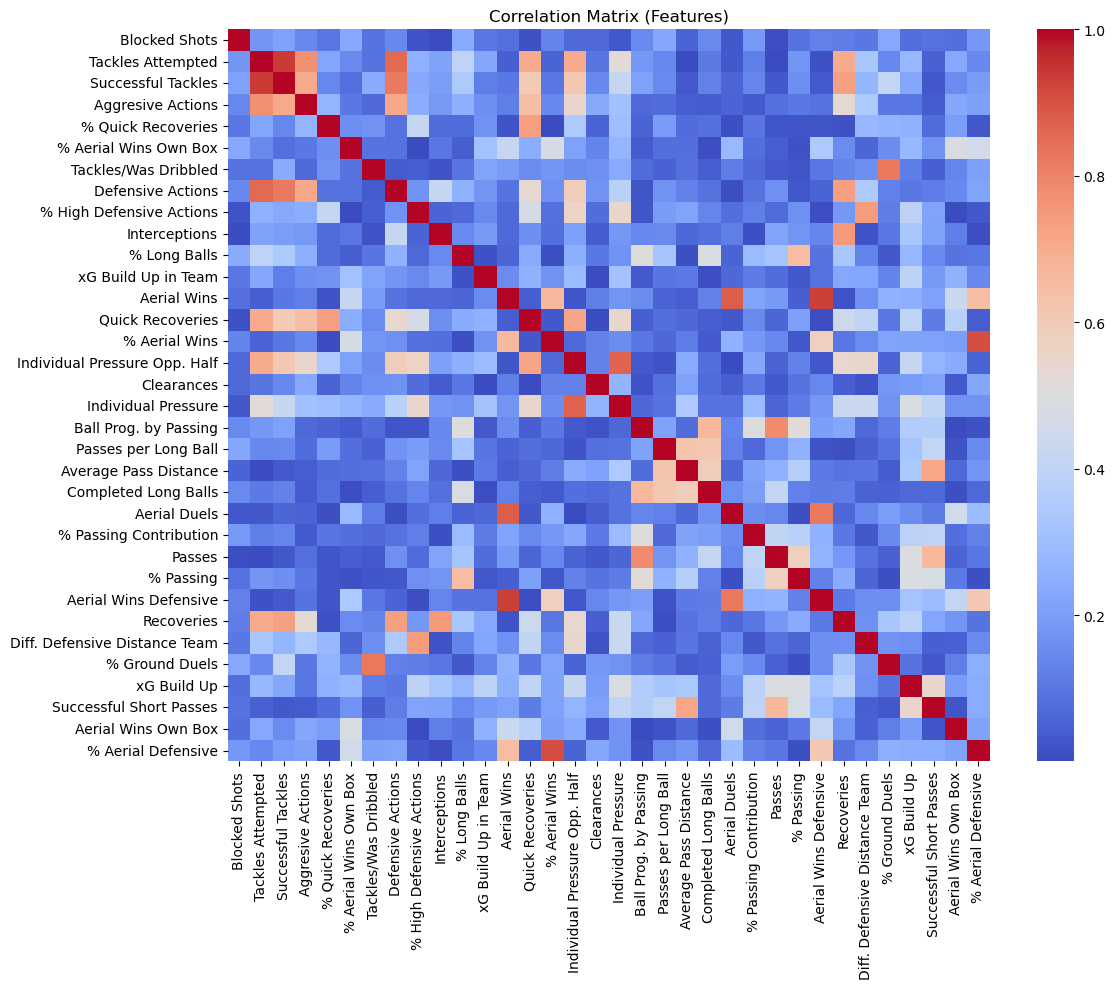

Detected 3 collinear features to remove: ['Successful Tackles', 'Aerial Wins Defensive', '% Aerial Defensive']

--- Running Logistic Regression Analysis ---
                              Logit Regression Results                              
Dep. Variable:     Significant_tmv_increase   No. Observations:                 2038
Model:                                Logit   Df Residuals:                     2006
Method:                                 MLE   Df Model:                           31
Date:                      Sun, 25 Jan 2026   Pseudo R-squ.:                 0.09910
Time:                              15:27:15   Log-Likelihood:                -824.83
converged:                             True   LL-Null:                       -915.56
Covariance Type:                  nonrobust   LLR p-value:                 3.415e-23
                                    coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------

In [10]:
cb_csv_path = project_root / "dataset_per_position" / "position_Centre_back.csv"

if cb_csv_path.exists():
    print(f"Testing with file: {cb_csv_path.name}")
    
    # 2. Pipeline Execution
    
    # A) Load & Filter -> Requires the KPI Dictionary
    df_cb = load_and_filter_kpis(
        csv_path=cb_csv_path, 
        kpi_dict=POSITION_KPIS  # <--- Explicitly passed
    )
    
    # B) Link Seasons -> No external config needed
    df_cb = parse_and_link_seasons(df_cb)
    print(f"Rows after linking: {len(df_cb)}")
    
    # C) Clean Data -> Requires missing threshold
    df_cb = clean_missing_data(
        df=df_cb, 
        missing_threshold=MISSING_THRESHOLD,  # <--- Explicitly passed
        min_minutes = MIN_MINUTES_CUTOFF
    )
    
    # D) Impute & Label -> Requires TMV threshold
    df_cb = impute_and_label(
        df=df_cb, 
        tmv_delta_threshold=TMV_DELTA_THRESHOLD # <--- Explicitly passed
    )
    
    # E) Collinearity & Regression
    df_cb = remove_collinear_features(df_cb, threshold=0.9)
    run_logistic_regression_analysis(df=df_cb)

else:
    print(f"File not found: {cb_csv_path}")